# Incompressible Field Exchange: Lid-driven Cavity

## Preamble

In [1]:
# Standard Library
from pathlib import Path

# FoamNordic
import foamnordic as fno

# Data and Numerical Computing
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
from IPython.display import display
import hedgehogs as hdg

### Directories

In [2]:
# Case Type and Name
CASE_TYPE = "laminar"
CASE_NAME = "lidDrivenCavity"
CATEGORY = "incompressible"

# FoamNordic Project Directory
PROJECT_DIR = Path.cwd().resolve()
BASE_DIR = next((path for path in (PROJECT_DIR, *PROJECT_DIR.parents) if (path / "tutorials" / "openfoam_tutorials").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Run this notebook from inside the FoamNordic source tree")
MAIN_DIR = BASE_DIR / "tutorials" / "foamnordic_tutorials" / CATEGORY
OF_SCRIPT_DIR = BASE_DIR / "tutorials" / "openfoam_tutorials" / CATEGORY / CASE_TYPE / CASE_NAME

# Output Directory
OUTPUT_DIR = MAIN_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

### Configuration

In [3]:
# Hedgehogs configuration
FIGURE_SIZE = hdg.figsize(column="double")
PALETTE = hdg.get_palette()
hdg.set_style()

In [4]:
# HPC configuration
ACCOUNT = "<allocation-account>"  # e.g. project_xxxxxxx
PARTITION = "test"
TIME = "00:15:00"
N_NODES = 1
N_TASKS = 1
CPUS_PER_TASK = 1
MEM_PER_CPU = "4G"

# FoamNordic Slurm configuration
of_scheduler = fno.Slurm.openfoam(
    nodes=N_NODES,
    ntasks=N_TASKS,
    cpus_per_task=CPUS_PER_TASK,
    mem_per_cpu=MEM_PER_CPU,
)

model_scheduler = fno.Slurm.model(
    cpus_per_task=1,
    mem_per_cpu=MEM_PER_CPU
)

scheduler = fno.Slurm(
    account=ACCOUNT,
    partition=PARTITION,
    time=TIME,
    openfoam=of_scheduler,
    model=model_scheduler
)

In [5]:
# FoamNordic configuration
SEED = 42
key = fno.Random.key(seed=SEED, scope="global")

## Example - Field Coupling

### Case Definition

In [6]:
# Define a custom operator to perturb the velocity field
def perturb_velocity(velocity, *, key):
    key, subkey = fno.Random.split(value=key, count=2)
    scale = fno.Random.uniform(value=subkey, low=0.995, high=1.005, shape=None)
    updated_velocity = velocity * scale
    return {"updated_velocity": updated_velocity}

velocity_transform = fno.Transform(
    name="perturbVelocity",
    operator=fno.Operator.function(function=perturb_velocity),
    inputs={"velocity": fno.Field(name="U")},
    outputs={"updated_velocity": fno.Field(name="U")},
    at="time_step_start",
    key=key,
)

In [7]:
# Initialize the OpenFOAM case
case = fno.OpenFOAM.Case(
    name="lidDrivenCavity",
    case_dir=OF_SCRIPT_DIR,
    run_dir=OUTPUT_DIR,
    of_cmd="module load openfoam/2512",
    shell="bash",
    application="pimpleFoam",
    ranks=N_TASKS,
)

case.initialize(ranks=N_TASKS, mesh="blockMesh", validate_mesh=True);

### Observation Definition

In [8]:
# Define field observations to monitor during the simulation
observations = fno.Observe(
    summaries={
        "U": ("min", "max", "mean", "l2"),
        "p": ("min", "max", "mean"),
    },
    interval=10,
)

### Submit Job

In [9]:
# Connect the OpenFOAM case and execution resources
longship = fno.Longship(
    case=case,
    transforms=(velocity_transform,),
    observations=(observations,),
    scheduler=scheduler,
    verbose=True,
)

Resource,OpenFOAM,Model,Allocation
Processes,1 tasks,1 host(s),1 node(s)
CPU,1 cores,1 cores,2 cores
Memory,4 GiB,4 GiB,8.03125 GiB
Field programs,-,1,1
SHM,-,~32 MiB,~32 MiB


In [10]:
# Launch the workload
run = longship.launch(verbose=None)

[FoamNordic] Preparing mesh with blockMesh: lidDrivenCavity
[FoamNordic] Mesh is ready: lidDrivenCavity
[FoamNordic] Sailing has launched with Job ID: 2657543
[FoamNordic] Sailing started at: 2026-10-30T07:38:50
[FoamNordic] Sailing in background: lidDrivenCavity


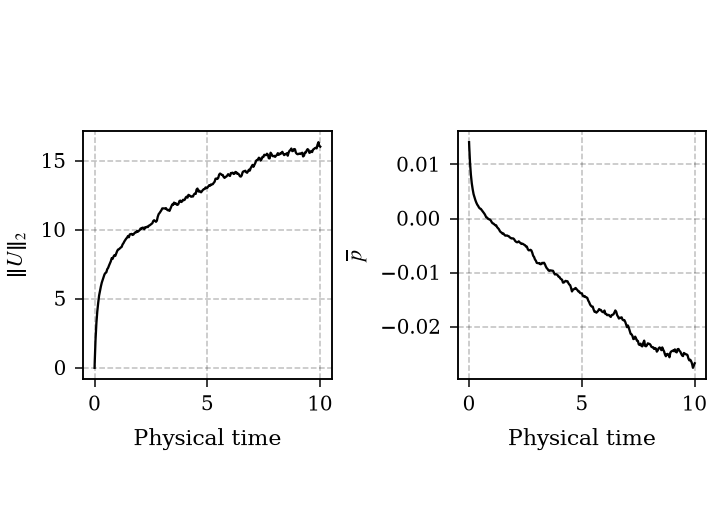

In [11]:
# Plot observations while the solver is running
records = []
figure, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE, layout="constrained")
hdg.plots.square(ax=axes)
velocity_line, = axes[0].plot([], [], color=PALETTE["black"])
pressure_line, = axes[1].plot([], [], color=PALETTE["black"])

axes[0].set_xlabel("Physical time")
axes[0].set_ylabel(r"$\Vert U \Vert_2$")
axes[1].set_xlabel("Physical time")
axes[1].set_ylabel(r"$\overline{p}$")

for axis in axes:
    hdg.plots.apply_grid(ax=axis)

display_handle = display(figure, display_id=True)

for record in run.observe(poll_interval=0.1, progress=True):
    records.append(record)
    physical_time = [item.time for item in records]
    velocity_l2 = [item.summary["U"].l2 for item in records]
    pressure_mean = [item.summary["p"].mean for item in records]

    velocity_line.set_data(physical_time, velocity_l2)
    pressure_line.set_data(physical_time, pressure_mean)

    for axis in axes:
        axis.relim()
        axis.autoscale_view()

    display_handle.update(figure)

plt.close(figure)

In [12]:
# Wait for the job to complete (polling the job status)
result = run.stop(force=False, timeout=3600, progress=True)

In [13]:
# Summary of the job result
result.summary(style="compact", display=True);

Job ID,Name,Status,Partition,Node,Elapsed
2657543,lidDrivenCavity,succeeded,test,rc4184,00:00:55


### Post-processing

In [14]:
# Postprocessing
post = result.postprocess

velocity = post.field(name="U", time_idx=-1, physical_time=None)
pressure = post.field(name="p", time_idx=-1, physical_time=None)

print("U shape:", velocity.shape)
print("p shape:", pressure.shape)

statistics = post.statistics(
    fields=["U", "p"],
    time_idx=-1,
    physical_time=None,
    verbose=True,
)

U shape: (4096, 3)
p shape: (4096,)


Field,Min,Max,Mean,Std,RMS
U,7.039078e-06,8.710882e-01,1.980805e-01,1.517841e-01,2.495482e-01
p,-1.209080e-01,6.000540e-01,-2.677977e-02,3.899099e-02,4.730173e-02


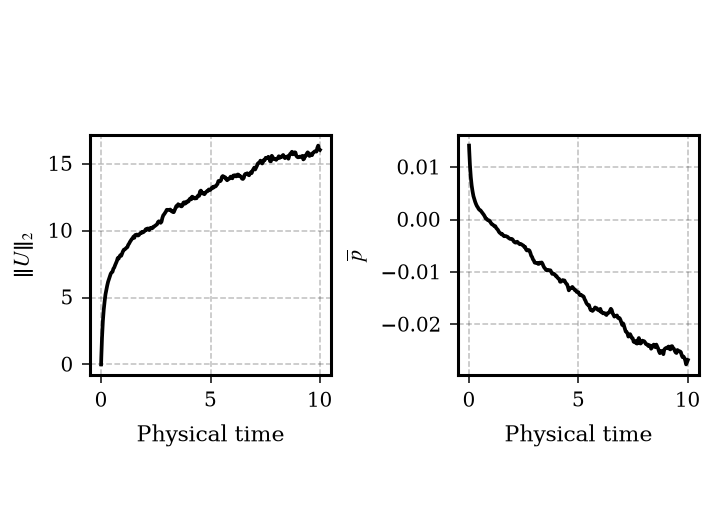

In [15]:
# Visualisation of the field statistics
physical_time = np.asarray([record.time for record in records])

def extract_stat(records, field, stat):
    return np.asarray([getattr(rec.summary[field], stat) for rec in records])

u_l2 = extract_stat(records, "U", "l2")
p_mean = extract_stat(records, "p", "mean")

fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE)

axes[0].plot(physical_time, u_l2, c=PALETTE["black"])
axes[0].set_xlabel("Physical time")
axes[0].set_ylabel(r"$\Vert U \Vert_2$")

axes[1].plot(physical_time, p_mean, c=PALETTE["black"])
axes[1].set_xlabel("Physical time")
axes[1].set_ylabel(r"$\overline{p}$")

for axis in axes:
    hdg.plots.apply_grid(ax=axis)

hdg.plots.square(ax=axes)
hdg.plots.show(fig=fig)

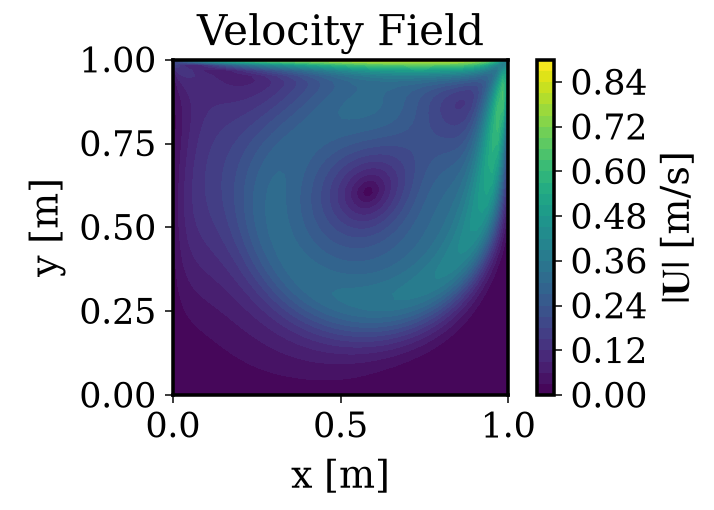

In [16]:
# Postprocessing with class
postprocessor = fno.Postprocess.Case(source=result)

# Load fields from the postprocessor (shape: (4096, 3) for U, (4096,) for p)
U = postprocessor.field(name="U", time_idx=-1, physical_time=None)
p = postprocessor.field(name="p", time_idx=-1, physical_time=None)

# Grid parameters for 2D lid-driven cavity (64x64 uniform grid, L = 1.0m)
n_cells = int(np.sqrt(len(U)))
L = 1.0
x = np.linspace(0, L, n_cells)
y = np.linspace(0, L, n_cells)
X, Y = np.meshgrid(x, y)

# Reshape field components to 2D structured mesh without transpose
u_x = U[:, 0].reshape(n_cells, n_cells)
u_y = U[:, 1].reshape(n_cells, n_cells)
u_mag = np.linalg.norm(U[:, :2], axis=1).reshape(n_cells, n_cells)
pressure_2d = p.reshape(n_cells, n_cells)

# Visualisation of velocity magnitude and streamlines
fig, ax = plt.subplots(figsize=FIGURE_SIZE)

contour = ax.contourf(X, Y, u_mag, levels=30, cmap="viridis")
cbar = fig.colorbar(contour, ax=ax)
hdg.plots.style_colorbar(cbar, label=r"$|\mathbf{U}|$ [m/s]")

ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Velocity Field")
ax.set_aspect("equal")

hdg.plots.square(ax=ax)
hdg.plots.show(fig=fig)